# Easy Deep Learning Practical Experiments

This notebook contains the 10 experiments previously classified as easy: **1, 2, 3, 5, 6, 13, 14, 15, 16 and 17**.

## How to use
1. Run the imports cell first.
2. Run the function-definition cells (they only define functions; they do not train models).
3. In the last cell, set `CHOICE` to one experiment number and run it. Run only one experiment at a time.

Install dependencies if needed: `pip install tensorflow scikit-learn pandas matplotlib numpy`. First-time dataset downloads need internet access.

## Imports and common setup

In [1]:
"""Easy Deep Learning Practicals (experiments 1, 2, 3, 5, 6, 13, 14, 15, 16, 17)

Run one experiment at a time:
    python easy_deep_learning_practicals.py
Then enter an experiment number when prompted.

Install dependencies:
    pip install tensorflow scikit-learn pandas matplotlib numpy

Notes:
- Some datasets are downloaded on first use and therefore require internet access.
- Experiment 2 uses scikit-learn's California Housing data downloader.
- Experiment 16 downloads the Jena Climate dataset from the URL used in the
  TensorFlow time-series tutorial.
"""

import os
import time
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.datasets import fetch_california_housing, load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    mean_absolute_error,
    mean_squared_error,
)

np.random.seed(42)
tf.random.set_seed(42)

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

## Experiment 1 — TensorFlow fundamentals, perceptron and MLP

Call `experiment_1_perceptron_and_mlp()` to run.

In [2]:
def experiment_1_perceptron_and_mlp():
    """TensorFlow tensor operations; compare single-layer perceptron and MLP on MNIST."""
    print("\n--- Basic TensorFlow tensor operations ---")
    a = tf.constant([1, 2, 3])
    b = tf.constant([4, 5, 6])
    print("Tensor a:", a.numpy())
    print("Tensor b:", b.numpy())
    print("Addition:", (a + b).numpy())
    print("Element-wise multiplication:", (a * b).numpy())
    print("2 x 3 matrix reshaped from 1..6:\n", tf.reshape(tf.range(1, 7), (2, 3)).numpy())

    (x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
    x_train = x_train.astype("float32") / 255.0
    x_test = x_test.astype("float32") / 255.0

    # A single-layer perceptron: no hidden dense layer.
    perceptron = keras.Sequential([
        keras.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(10, activation="softmax"),
    ])
    perceptron.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    perceptron.fit(x_train, y_train, epochs=3, batch_size=128, validation_split=0.1, verbose=1)
    p_loss, p_acc = perceptron.evaluate(x_test, y_test, verbose=0)

    # An MLP adds a hidden layer.
    mlp = keras.Sequential([
        keras.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ])
    mlp.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    mlp.fit(x_train, y_train, epochs=3, batch_size=128, validation_split=0.1, verbose=1)
    m_loss, m_acc = mlp.evaluate(x_test, y_test, verbose=0)

    print(f"Perceptron test accuracy: {p_acc:.4f}")
    print(f"MLP test accuracy:        {m_acc:.4f}")

## Experiment 2 — California Housing regression

Call `experiment_2_house_price_regression()` to run. Requires downloading the California Housing dataset.

In [3]:
def experiment_2_house_price_regression():
    """California Housing regression with L1, L2, and dropout variants."""
    print("Downloading/loading California Housing data (internet may be required)...")
    data = fetch_california_housing()
    x_train, x_test, y_train, y_test = train_test_split(
        data.data, data.target, test_size=0.2, random_state=42
    )
    scaler = StandardScaler()
    x_train = scaler.fit_transform(x_train).astype("float32")
    x_test = scaler.transform(x_test).astype("float32")
    y_train = y_train.astype("float32")
    y_test = y_test.astype("float32")

    def build_model(kind):
        if kind == "L1":
            regularizer = keras.regularizers.l1(0.001)
        elif kind == "L2":
            regularizer = keras.regularizers.l2(0.001)
        else:
            regularizer = None
        model_layers = [keras.Input(shape=(x_train.shape[1],)), layers.Dense(64, activation="relu", kernel_regularizer=regularizer)]
        if kind == "Dropout":
            model_layers.append(layers.Dropout(0.2))
        model_layers.extend([layers.Dense(32, activation="relu", kernel_regularizer=regularizer), layers.Dense(1)])
        model = keras.Sequential(model_layers)
        model.compile(optimizer="adam", loss="mse", metrics=["mae"])
        return model

    for kind in ["L1", "L2", "Dropout"]:
        print(f"\nTraining model with {kind}...")
        model = build_model(kind)
        model.fit(x_train, y_train, epochs=15, batch_size=64, validation_split=0.2, verbose=0)
        loss, mae = model.evaluate(x_test, y_test, verbose=0)
        print(f"{kind}: Test MSE={loss:.4f}, Test MAE={mae:.4f}, Test RMSE={np.sqrt(loss):.4f}")

## Experiment 3 — CNN classification on CIFAR-10

Call `experiment_3_cnn_cifar10()` to run.

In [4]:
def experiment_3_cnn_cifar10():
    """Classify CIFAR-10 images; demonstrate dropout, model saving, and reloading."""
    (x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
    x_train = x_train.astype("float32") / 255.0
    x_test = x_test.astype("float32") / 255.0
    y_train = y_train.squeeze()
    y_test = y_test.squeeze()

    model = keras.Sequential([
        keras.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation="relu", padding="same"),
        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    model.summary()
    model.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1, verbose=1)
    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
    print(f"Original model: test loss={loss:.4f}, accuracy={accuracy:.4f}")

    save_path = "cifar10_cnn.keras"
    model.save(save_path)
    print(f"Saved model to: {save_path}")
    loaded_model = keras.models.load_model(save_path)
    loaded_loss, loaded_accuracy = loaded_model.evaluate(x_test, y_test, verbose=0)
    print(f"Reloaded model: test loss={loaded_loss:.4f}, accuracy={loaded_accuracy:.4f}")

## Experiment 5 — Sentiment analysis with RNN, LSTM and GRU

Call `experiment_5_imdb_rnn_lstm_gru()` to run.

In [5]:
def experiment_5_imdb_rnn_lstm_gru():
    """Compare SimpleRNN, LSTM, and GRU for positive/negative IMDB review sentiment."""
    vocab_size = 10000
    max_length = 200
    (x_train, y_train), (x_test, y_test) = keras.datasets.imdb.load_data(num_words=vocab_size)
    x_train = keras.utils.pad_sequences(x_train, maxlen=max_length, padding="post", truncating="post")
    x_test = keras.utils.pad_sequences(x_test, maxlen=max_length, padding="post", truncating="post")

    results = {}
    for cell_name in ["SimpleRNN", "LSTM", "GRU"]:
        print(f"\nTraining {cell_name} model...")
        if cell_name == "SimpleRNN":
            recurrent_layer = layers.SimpleRNN(32)
        elif cell_name == "LSTM":
            recurrent_layer = layers.LSTM(32)
        else:
            recurrent_layer = layers.GRU(32)

        model = keras.Sequential([
            keras.Input(shape=(max_length,), dtype="int32"),
            layers.Embedding(vocab_size, 64),
            recurrent_layer,
            layers.Dense(1, activation="sigmoid"),
        ])
        model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
        start = time.time()
        model.fit(x_train, y_train, epochs=2, batch_size=128, validation_split=0.1, verbose=1)
        seconds = time.time() - start
        loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
        results[cell_name] = (accuracy, seconds)
        print(f"{cell_name}: test accuracy={accuracy:.4f}; training time={seconds:.1f}s")

    print("\nComparison:")
    for name, (accuracy, seconds) in results.items():
        print(f"{name:10s} accuracy={accuracy:.4f}, training_time={seconds:.1f}s")

## Experiment 6 — Basic autoencoder

Call `experiment_6_basic_autoencoder()` to run.

In [6]:
def experiment_6_basic_autoencoder():
    """Compress and reconstruct MNIST digit images with a dense autoencoder."""
    (x_train, _), (x_test, _) = keras.datasets.mnist.load_data()
    x_train = x_train.astype("float32").reshape(-1, 784) / 255.0
    x_test = x_test.astype("float32").reshape(-1, 784) / 255.0

    model = keras.Sequential([
        keras.Input(shape=(784,)),
        layers.Dense(128, activation="relu"),
        layers.Dense(32, activation="relu", name="encoded"),
        layers.Dense(128, activation="relu"),
        layers.Dense(784, activation="sigmoid"),
    ])
    model.compile(optimizer="adam", loss="mse")
    model.summary()
    model.fit(x_train, x_train, epochs=5, batch_size=256, validation_split=0.1, verbose=1)

    reconstructed = model.predict(x_test[:10], verbose=0)
    reconstruction_mse = np.mean((x_test - model.predict(x_test, batch_size=256, verbose=0)) ** 2)
    print(f"Test reconstruction MSE: {reconstruction_mse:.6f}")

    fig, axes = plt.subplots(2, 10, figsize=(13, 3))
    for i in range(10):
        axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
        axes[0, i].set_title("Original")
        axes[1, i].imshow(reconstructed[i].reshape(28, 28), cmap="gray")
        axes[1, i].set_title("Reconstructed")
        axes[0, i].axis("off")
        axes[1, i].axis("off")
    plt.tight_layout()
    plt.show()

## Experiment 13 — MLP on Fashion-MNIST

Call `experiment_13_fashion_mnist_mlp()` to run.

In [7]:
def experiment_13_fashion_mnist_mlp():
    """Compare MLP depth, width, and activation on Fashion-MNIST."""
    (x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
    x_train = x_train.astype("float32") / 255.0
    x_test = x_test.astype("float32") / 255.0

    configurations = [
        ("One hidden layer, ReLU", [64], "relu"),
        ("Two hidden layers, ReLU", [128, 64], "relu"),
        ("Two hidden layers, tanh", [128, 64], "tanh"),
    ]
    for label, units_list, activation in configurations:
        print(f"\nTraining: {label}")
        model_layers = [keras.Input(shape=(28, 28)), layers.Flatten()]
        for units in units_list:
            model_layers.append(layers.Dense(units, activation=activation))
        model_layers.append(layers.Dense(10, activation="softmax"))
        model = keras.Sequential(model_layers)
        model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        model.fit(x_train, y_train, epochs=3, batch_size=128, validation_split=0.1, verbose=1)
        loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
        print(f"{label}: test accuracy={accuracy:.4f}")

## Experiment 14 — Breast Cancer binary classification

Call `experiment_14_breast_cancer_binary_classification()` to run.

In [8]:
def experiment_14_breast_cancer_binary_classification():
    """Binary classification using Wisconsin Breast Cancer dataset."""
    data = load_breast_cancer()
    x_train, x_test, y_train, y_test = train_test_split(
        data.data, data.target, test_size=0.2, random_state=42, stratify=data.target
    )
    scaler = StandardScaler()
    x_train = scaler.fit_transform(x_train).astype("float32")
    x_test = scaler.transform(x_test).astype("float32")

    model = keras.Sequential([
        keras.Input(shape=(x_train.shape[1],)),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    model.summary()
    model.fit(x_train, y_train, epochs=20, batch_size=32, validation_split=0.2, verbose=1)

    probabilities = model.predict(x_test, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype("int32")
    print("Test accuracy:", np.mean(predictions == y_test).round(4))
    print("Confusion matrix:\n", confusion_matrix(y_test, predictions))
    print(classification_report(y_test, predictions, target_names=data.target_names))

## Experiment 15 — Wine multiclass classification

Call `experiment_15_wine_multiclass_classification()` to run.

In [9]:
def experiment_15_wine_multiclass_classification():
    """Three-class wine classification with softmax and categorical cross-entropy."""
    data = load_wine()
    x_train, x_test, y_train, y_test = train_test_split(
        data.data, data.target, test_size=0.2, random_state=42, stratify=data.target
    )
    scaler = StandardScaler()
    x_train = scaler.fit_transform(x_train).astype("float32")
    x_test = scaler.transform(x_test).astype("float32")
    y_train_onehot = keras.utils.to_categorical(y_train, num_classes=3)

    model = keras.Sequential([
        keras.Input(shape=(x_train.shape[1],)),
        layers.Dense(32, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(3, activation="softmax"),
    ])
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    model.summary()
    model.fit(x_train, y_train_onehot, epochs=50, batch_size=16, validation_split=0.2, verbose=1)

    probabilities = model.predict(x_test, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    accuracy = np.mean(predictions == y_test)
    precision = precision_score(y_test, predictions, average="weighted", zero_division=0)
    recall = recall_score(y_test, predictions, average="weighted", zero_division=0)
    print(f"Test accuracy:  {accuracy:.4f}")
    print(f"Weighted precision: {precision:.4f}")
    print(f"Weighted recall:    {recall:.4f}")
    print("Confusion matrix:\n", confusion_matrix(y_test, predictions))
    print(classification_report(y_test, predictions, target_names=data.target_names, zero_division=0))

## Experiment 16 — Jena Climate LSTM forecasting

Call `experiment_16_jena_climate_lstm_forecasting()` to run. Requires internet for the first dataset download.

In [10]:
def experiment_16_jena_climate_lstm_forecasting():
    """Forecast the next hourly temperature from the previous 24 hourly readings."""
    url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip"
    zip_path = keras.utils.get_file("jena_climate_2009_2016.csv.zip", origin=url, extract=False)
    extract_dir = Path(zip_path).parent / "jena_climate_extracted"
    csv_path = extract_dir / "jena_climate_2009_2016.csv"
    if not csv_path.exists():
        extract_dir.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(zip_path, "r") as archive:
            archive.extractall(extract_dir)

    df = pd.read_csv(csv_path)
    # Original readings are 10-minute intervals; take every 6th row for hourly data.
    temperature = df["T (degC)"].to_numpy(dtype=np.float32)[::6]
    sequence_length = 24  # previous 24 hours
    split_point = int(len(temperature) * 0.8)
    mean = temperature[:split_point].mean()
    std = temperature[:split_point].std() + 1e-7
    normalized = (temperature - mean) / std

    windows = np.lib.stride_tricks.sliding_window_view(normalized, sequence_length + 1)
    x = windows[:, :-1].copy()[..., np.newaxis]
    y = windows[:, -1].copy()
    split = int(len(x) * 0.8)
    x_train, x_test = x[:split], x[split:]
    y_train, y_test = y[:split], y[split:]

    model = keras.Sequential([
        keras.Input(shape=(sequence_length, 1)),
        layers.LSTM(32),
        layers.Dense(1),
    ])
    model.compile(optimizer="adam", loss="mse", metrics=["mae"])
    model.summary()
    model.fit(x_train, y_train, epochs=3, batch_size=256, validation_split=0.1, verbose=1)

    prediction_norm = model.predict(x_test, batch_size=256, verbose=0).ravel()
    prediction = prediction_norm * std + mean
    actual = y_test * std + mean
    mae = mean_absolute_error(actual, prediction)
    rmse = np.sqrt(mean_squared_error(actual, prediction))
    print(f"Test MAE:  {mae:.3f} °C")
    print(f"Test RMSE: {rmse:.3f} °C")

    plt.figure(figsize=(10, 4))
    plt.plot(actual[:200], label="Actual temperature")
    plt.plot(prediction[:200], label="Predicted temperature")
    plt.xlabel("Test hour")
    plt.ylabel("Temperature (°C)")
    plt.title("Jena Climate: actual vs predicted temperature")
    plt.legend()
    plt.tight_layout()
    plt.show()

## Experiment 17 — Denoising autoencoder

Call `experiment_17_denoising_autoencoder()` to run.

In [11]:
def experiment_17_denoising_autoencoder():
    """Add noise to MNIST images and train an autoencoder to reconstruct clean images."""
    (x_train, _), (x_test, _) = keras.datasets.mnist.load_data()
    x_train = x_train.astype("float32") / 255.0
    x_test = x_test.astype("float32") / 255.0

    rng = np.random.default_rng(42)
    x_train_noisy = np.clip(x_train + rng.normal(0, 0.3, x_train.shape), 0.0, 1.0)
    x_test_noisy = np.clip(x_test + rng.normal(0, 0.3, x_test.shape), 0.0, 1.0)
    x_train_noisy = x_train_noisy.reshape(-1, 784)
    x_test_noisy = x_test_noisy.reshape(-1, 784)
    x_train_clean = x_train.reshape(-1, 784)
    x_test_clean = x_test.reshape(-1, 784)

    model = keras.Sequential([
        keras.Input(shape=(784,)),
        layers.Dense(256, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(256, activation="relu"),
        layers.Dense(784, activation="sigmoid"),
    ])
    model.compile(optimizer="adam", loss="mse")
    model.summary()
    model.fit(x_train_noisy, x_train_clean, epochs=5, batch_size=256, validation_split=0.1, verbose=1)

    denoised = model.predict(x_test_noisy[:10], verbose=0)
    full_predictions = model.predict(x_test_noisy, batch_size=256, verbose=0)
    mse = np.mean((x_test_clean - full_predictions) ** 2)
    psnr = 20 * np.log10(1.0 / (np.sqrt(mse) + 1e-10))
    print(f"Test reconstruction MSE: {mse:.6f}")
    print(f"Approximate PSNR: {psnr:.2f} dB")

    fig, axes = plt.subplots(3, 10, figsize=(13, 4))
    for i in range(10):
        axes[0, i].imshow(x_test_clean[i].reshape(28, 28), cmap="gray")
        axes[1, i].imshow(x_test_noisy[i].reshape(28, 28), cmap="gray")
        axes[2, i].imshow(denoised[i].reshape(28, 28), cmap="gray")
        for row in range(3):
            axes[row, i].axis("off")
    axes[0, 0].set_ylabel("Original", fontsize=9)
    axes[1, 0].set_ylabel("Noisy", fontsize=9)
    axes[2, 0].set_ylabel("Denoised", fontsize=9)
    plt.tight_layout()
    plt.show()

## Select and run one experiment

Running: Denoising autoencoder (MNIST)


Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_33 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 256)            │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 435,536 (1.66 MB)

 Trainable params: 435,536 (1.66 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0856 - val_loss: 0.0325
Epoch 2/5
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0292 - val_loss: 0.0220
Epoch 3/5
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0209 - val_loss: 0.0181
Epoch 4/5
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0176 - val_loss: 0.0162
Epoch 5/5
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0156 - val_loss: 0.0148
Test reconstruction MSE: 0.014462
Approximate PSNR: 18.40 dB


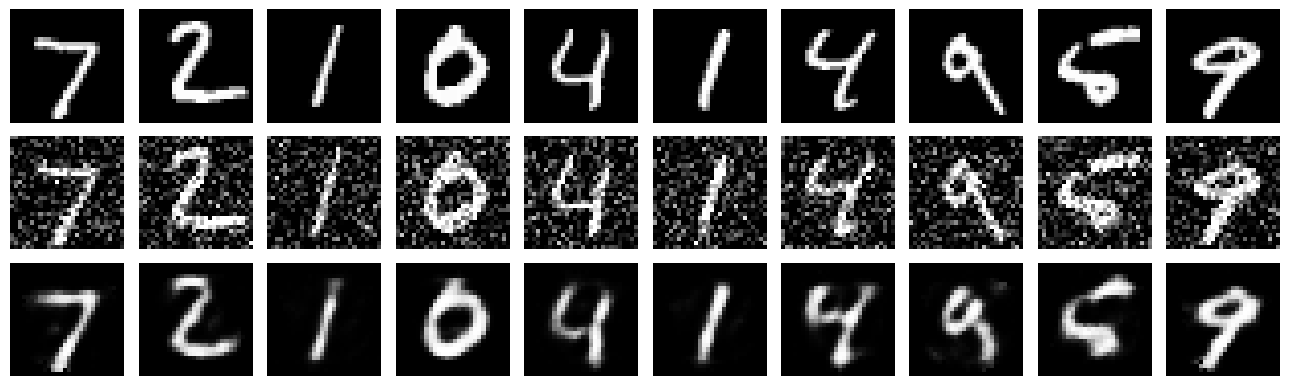

In [22]:
EXPERIMENTS = {
    "1": ("TensorFlow tensors + Perceptron and MLP", experiment_1_perceptron_and_mlp),
    "2": ("California Housing regression (L1/L2/Dropout)", experiment_2_house_price_regression),
    "3": ("CNN image classification (CIFAR-10)", experiment_3_cnn_cifar10),
    "5": ("Sentiment analysis (RNN/LSTM/GRU)", experiment_5_imdb_rnn_lstm_gru),
    "6": ("Basic autoencoder (MNIST)", experiment_6_basic_autoencoder),
    "13": ("MLP classification (Fashion-MNIST)", experiment_13_fashion_mnist_mlp),
    "14": ("Binary classification (Breast Cancer)", experiment_14_breast_cancer_binary_classification),
    "15": ("Multiclass classification (Wine)", experiment_15_wine_multiclass_classification),
    "16": ("LSTM time-series forecasting (Jena Climate)", experiment_16_jena_climate_lstm_forecasting),
    "17": ("Denoising autoencoder (MNIST)", experiment_17_denoising_autoencoder),
}

CHOICE = "17"  # Change to: "2", "3", "5", "6", "13", "14", "15", "16", or "17"
if CHOICE not in EXPERIMENTS:
    raise ValueError("Choose one of the listed experiment numbers")
print("Running:", EXPERIMENTS[CHOICE][0])
EXPERIMENTS[CHOICE][1]()